<a href="https://colab.research.google.com/github/isadesabrit/CollisionModel_Simulation/blob/main/Collision_Model_Simulation_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Numerical** **Simulation** **of** **Non**-**Markovian** **Dynamics** **on** **All**-**to**-**All** **Collision** **Models**

In [22]:
!pip install -q qiskit qiskit-aer matplotlib

import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__)

qiskit 2.6.2 | aer 0.18.4


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, transpile
from qiskit.circuit.library import HamiltonianGate
import qiskit.quantum_info as qi
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

In [24]:
# Preparing the mixed resevoir
def make_init_gate():
    init = QuantumCircuit(QuantumRegister(3, "R"), QuantumRegister(3, "Anc"))
    #6 qubit sub circuit, 3 qubits and 3 ancillas
    # 0, 1, 2 are reservoir and 3, 4, 5 are ancillas

    for i in range(3):
        init.h(i)

        # Entangle reservoir qubit with ancilla i+3
        # Leads to reservoir qubits being maximally entangled with ancillas
        init.cx(i, i + 3)

    return init.to_gate(label="Initialisation")
INIT_GATE = make_init_gate()

In [25]:
# Partial swap
# Returns the 4X4 unitary
def partial_swap(eta):
    c = np.cos(eta)
    s = np.sin(eta)

    return qi.Operator(np.array([
        [c + 1j*s, 0,    0,    0       ],
        [0,        c,    1j*s, 0       ],
        [0,        1j*s, c,    0       ],
        [0,        0,    0,    c + 1j*s]], dtype=complex))

assert partial_swap(1.26).is_unitary()

In [26]:
# Heisenberg Chain
def heisenberg_H(J=10, B=0.0):

    # Constructs the 8x8 Hamiltonian for the three-qubit system
    # J controls excitation hopping; B controls the local Z-field

    H = np.array([
        [-3*B, 0,   0,  0,  0,  0,  0,   0  ],
        [0,   -B,   J,  0,  0,  0,  0,   0  ],
        [0,    J,  -B,  0,  J,  0,  0,   0  ],
        [0,    0,   0,  B,  0,  J,  0,   0  ],
        [0,    0,   J,  0, -B,  0,  0,   0  ],
        [0,    0,   0,  J,  0,  B,  J,   0  ],
        [0,    0,   0,  0,  0,  J,  B,   0  ],
        [0,    0,   0,  0,  0,  0,  0,   3*B]], dtype=complex)

    # Hermitian is required, otherwise exp(-iHt) would not be unitary
    assert np.allclose(H, H.conj().T), "H must be Hermitian"
    return H

H_HEIS = heisenberg_H()

In [27]:
# Finds the right matrix index
IDX_S1, IDX_S3 = 1, 4

for qubit in range(3):
    ket = "".join("1" if q == qubit else "0" for q in reversed(range(3)))
    print(f"S{qubit+1} excited -> Qiskit ket |{ket}> -> index {int(ket, 2)}")


S1 excited -> Qiskit ket |001> -> index 1
S2 excited -> Qiskit ket |010> -> index 2
S3 excited -> Qiskit ket |100> -> index 4


In [28]:
# Builds the depolarizing noise model
def depolarizing_channel(omega):
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(depolarizing_error(omega, 1), ["id"])
    return noise_model

def apply_depolarizing(qc, qubits):
    qc.id(qubits)

In [29]:
#Program steps:
#1) Initialization
#2) Protocol (homogenisation -> depolarising -> Heisenberg), repeated num_rounds times (30 in this case)
#3) Extraction

def initialize_system(qc):
    qc.append(INIT_GATE, [3, 4, 5, 6, 7, 8])   # reservoir + ancillas

    qc.x(0)
    # Pauli X on S1: |0> becomes |1>.

def build_circuit(eta, num_rounds, t=0.1, H=None):

    H = H_HEIS if H is None else H

    # Nine qubits: 3 in the system, 3 in the reservoir, and 3 ancillas
    qc = QuantumCircuit(9)
    initialize_system(qc)

    p = partial_swap(eta)
    heis_gate = HamiltonianGate(H, t, label="Heis Chain")

    for k in range(1, num_rounds + 1):

        # Quantum homogeniser: each system qubit collides, in order, with every environment qubit
        for sys_q in (0, 1, 2):
            for env_q in (3, 4, 5):
                qc.unitary(p, [sys_q, env_q])

        # Depolarising channel acting on the environment
        apply_depolarizing(qc, [3, 4, 5])

        # One Heisenberg step on the system chain --> transports the excitation between S1, S2, S3 and creates coherence.
        qc.append(heis_gate, [0, 1, 2])

        qc.save_density_matrix([0, 1, 2], label=f"round_{k}")

    return qc

In [30]:
def run(eta, omega, num_rounds, t=0.1):
    """Returns |rho_C^(1,3)(k)| for k = 1 .. num_rounds."""
    qc = build_circuit(eta, num_rounds, t=t)
    noise_model = depolarizing_channel(omega)
    sim = AerSimulator(noise_model=noise_model)

    #  Disable transpiler optimizations to preserve identity gates used to implement the depolarizing noise channel
    tqc = transpile(qc, sim, optimization_level=0)
    assert tqc.count_ops().get("id", 0) > 0, "id gates were optimised"

    data = sim.run(tqc).result().data()

    # Read the single entry at [1, 4]
    coherences = np.empty(num_rounds)
    for k in range(1, num_rounds + 1):
        rho_k = np.asarray(data[f"round_{k}"])
        coherences[k - 1] = abs(rho_k[IDX_S1, IDX_S3])
    return coherences

**Results**

In [31]:
etas = np.linspace(0, np.pi / 2, 5)    # 0, pi/8, pi/4, 3pi/8, pi/2
omegas = np.linspace(0, 1, 5)          # 0, 0.25, 0.5, 0.75, 1
results = {}
for eta in etas:
    for omega in omegas:
        results[(eta, omega)] = run(eta=eta, omega=omega, num_rounds=30)

import pandas as pd

def results_table(results, decimals=4):
    rows = []
    for (eta, omega), values in results.items():
        row = {"eta": eta, "omega": omega}
        for k, v in enumerate(values, start=1):
            row[f"round_{k}"] = v
        rows.append(row)

    df = pd.DataFrame(rows)
    return df.round(decimals)

table = results_table(results)
print(table.to_string(index=False))

   eta  omega  round_1  round_2  round_3  round_4  round_5  round_6  round_7  round_8  round_9  round_10  round_11  round_12  round_13  round_14  round_15  round_16  round_17  round_18  round_19  round_20  round_21  round_22  round_23  round_24  round_25  round_26  round_27  round_28  round_29  round_30
0.0000   0.00   0.2439   0.0237   0.1988   0.0859   0.1256   0.1629   0.0522   0.2255   0.0065    0.2500    0.0057    0.2270    0.0502    0.1653    0.1231    0.0883    0.1968    0.0252    0.2431    0.0000    0.2447    0.0223    0.2008    0.0835    0.1281    0.1605    0.0543    0.2240    0.0073    0.2499
0.0000   0.25   0.2439   0.0237   0.1988   0.0859   0.1256   0.1629   0.0522   0.2255   0.0065    0.2500    0.0057    0.2270    0.0502    0.1653    0.1231    0.0883    0.1968    0.0252    0.2431    0.0000    0.2447    0.0223    0.2008    0.0835    0.1281    0.1605    0.0543    0.2240    0.0073    0.2499
0.0000   0.50   0.2439   0.0237   0.1988   0.0859   0.1256   0.1629   0.0522   0.2255

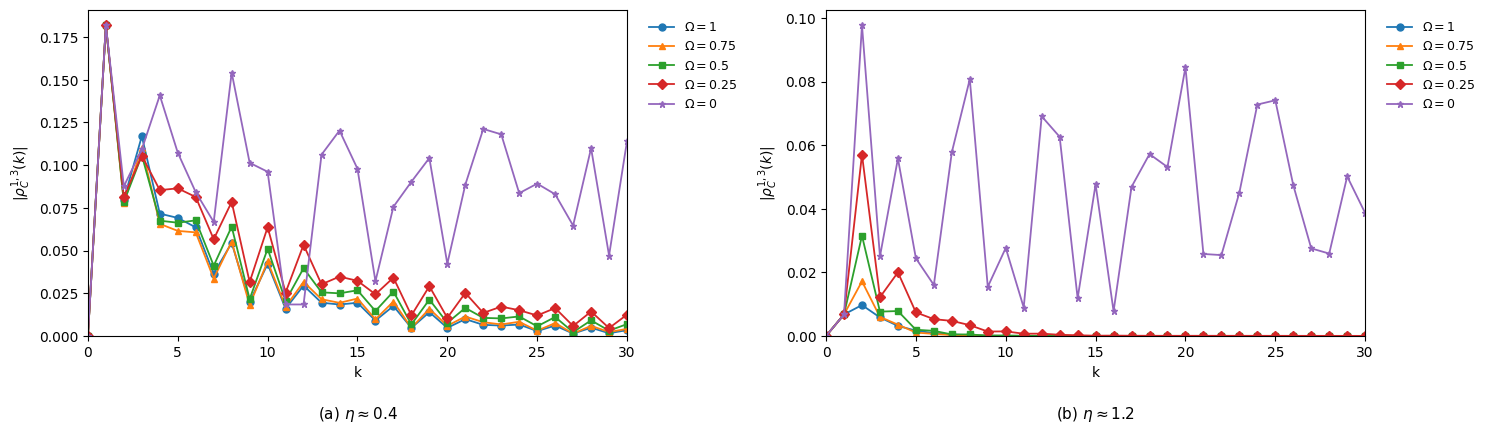

In [32]:
ks = np.arange(0, 31)
styles = [
    (1.00, "tab:blue",   "o", r"$\Omega = 1$"),
    (0.75, "tab:orange", "^", r"$\Omega = 0.75$"),
    (0.50, "tab:green",  "s", r"$\Omega = 0.5$"),
    (0.25, "tab:red",    "D", r"$\Omega = 0.25$"),
    (0.00, "tab:purple", "*", r"$\Omega = 0$"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, eta, title in [(axes[0], etas[1], r"(a) $\eta \approx 0.4$"),
                       (axes[1], etas[3], r"(b) $\eta \approx 1.2$")]:
    for omega, color, marker, label in styles:
        y = np.concatenate(([0.0], results[(eta, omegas[int(round(omega * 4))])]))
        ax.plot(ks, y, color=color, marker=marker, markersize=5, linewidth=1.3, label=label)
    ax.set_xlim(0, 30)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("k")
    ax.set_ylabel(r"$|\rho_C^{1,3}(k)|$")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=9, frameon=False)
    ax.set_title(title, y=-0.28, fontsize=11)

plt.tight_layout()
plt.show()